# 16 — Solar Battery Optimizer & Energy Management Simulation

**Objective:** Convert irradiance predictions from the Chronos fine-tuned model into actionable solar PV output, simulate a residential battery storage system with real household load data, and evaluate energy self-sufficiency across Indian cities.

**Pipeline:**
1. Load 24h irradiance predictions (W/m²) → Convert to solar PV output (kW)
2. Load real household electricity consumption (UCI dataset) → Resample & scale to Indian residential levels
3. Run hour-by-hour battery dispatch with greedy look-ahead
4. Compute KPIs: self-sufficiency, CO₂ avoided, peak hours avoided, solar self-consumption
5. Visualize energy flows, battery state, grid dependency, and cross-city comparison

## 1. Setup & Configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import json
import os
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.figsize': (14, 6),
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.dpi': 120,
    'savefig.dpi': 150,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

# ── Paths ──
BASE_DIR = '.'
RESULTS_DIR = os.path.join(BASE_DIR, 'results')
WINDOWS_DIR = os.path.join(BASE_DIR, 'data', 'processed', 'windows')
METADATA_PATH = os.path.join(BASE_DIR, 'data', 'metadata', 'city_info.json')
LOAD_DATA_PATH = os.path.join(BASE_DIR, 'individual+household+electric+power+consumption', 'household_power_consumption.txt')
OUTPUT_DIR = os.path.join(RESULTS_DIR, 'battery_optimizer')
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── City metadata ──
with open(METADATA_PATH) as f:
    CITY_INFO = json.load(f)
ALL_CITIES = list(CITY_INFO.keys())

# ── PV Panel Configuration ──
# Note: panel_peak_kw is the STC rating which already includes cell efficiency.
# system_derating accounts for temperature, soiling, mismatch, wiring losses.
PV_CONFIG = {
    'panel_peak_kw': 2.5,           # Small rooftop system (kW) — STC rating
    'system_derating': 0.85,         # Temperature + soiling + mismatch + wiring
    'inverter_efficiency': 0.96,     # 96% string inverter
    'min_irradiance_threshold': 50,  # W/m² — below this, output = 0
}

# ── Battery Configuration ──
BATTERY_CONFIG = {
    'capacity_kwh': 5.0,            # Total battery capacity
    'max_charge_kw': 2.5,           # 0.5C charge rate
    'max_discharge_kw': 2.5,        # 0.5C discharge rate
    'roundtrip_efficiency': 0.92,   # 92% round-trip
    'charge_efficiency': np.sqrt(0.92),    # ~95.9% each way
    'discharge_efficiency': np.sqrt(0.92), # ~95.9% each way
    'min_soc': 0.10,                # 10% minimum
    'max_soc': 0.95,                # 95% maximum
    'initial_soc': 0.20,            # Start at 20%
}

# ── Grid & Emissions ──
GRID_CONFIG = {
    'india_emission_factor': 0.82,  # kg CO₂ per kWh (India grid average 2024)
    'peak_hours': list(range(18, 22)),  # 6 PM - 10 PM
}

# ── Load profile scaling ──
# UCI French household: ~26 kWh/day avg
# Indian urban middle-class: ~12-15 kWh/day
LOAD_SCALE_FACTOR = 0.50  # Scale down to Indian levels

print("Configuration loaded!")
print(f"  PV System:  {PV_CONFIG['panel_peak_kw']} kW panel, {PV_CONFIG['system_derating']*100:.0f}% derating, {PV_CONFIG['inverter_efficiency']*100:.0f}% inverter")
print(f"  Battery:    {BATTERY_CONFIG['capacity_kwh']} kWh, {BATTERY_CONFIG['max_charge_kw']} kW charge/discharge")
print(f"  SOC Range:  {BATTERY_CONFIG['min_soc']*100:.0f}% – {BATTERY_CONFIG['max_soc']*100:.0f}%")
print(f"  Cities:     {len(ALL_CITIES)} ({', '.join(ALL_CITIES)})")
print(f"  CO2 Factor: {GRID_CONFIG['india_emission_factor']} kg/kWh (India grid)")

Configuration loaded!
  PV System:  2.5 kW panel, 85% derating, 96% inverter
  Battery:    5.0 kWh, 2.5 kW charge/discharge
  SOC Range:  10% – 95%
  Cities:     12 (jaipur, delhi, guwahati, ahmedabad, chennai, thiruvananthapuram, nagpur, hyderabad, bangalore, kolkata, lucknow, jodhpur)
  CO2 Factor: 0.82 kg/kWh (India grid)


## 2. Load Irradiance Predictions

Load the 24h irradiance forecasts from the Chronos fine-tuned model (best performing) and ground truth targets for all 12 cities.

In [2]:
# ── Load predictions and ground truth for all cities ──
predictions = {}
ground_truth = {}

for city in ALL_CITIES:
    # Predictions (Chronos fine-tuned)
    pred_path = os.path.join(RESULTS_DIR, f'pred_chronos_finetuned_{city}.npy')
    if os.path.exists(pred_path):
        predictions[city] = np.load(pred_path)
    
    # Ground truth targets — try both naming conventions
    tgt_path = os.path.join(WINDOWS_DIR, f'{city}_test_targets.npy')
    if not os.path.exists(tgt_path):
        tgt_path = os.path.join(WINDOWS_DIR, f'test_{city}_targets.npy')
    if os.path.exists(tgt_path):
        ground_truth[city] = np.load(tgt_path)

print(f"Loaded predictions for {len(predictions)} cities, ground truth for {len(ground_truth)} cities\n")

# Show shapes and sample stats
print(f"{'City':<22} {'Pred Shape':<16} {'Target Shape':<16} {'Pred Mean W/m²':<16} {'Pred Max W/m²'}")
print("─" * 90)
for city in sorted(predictions.keys()):
    pred = predictions[city]
    tgt_shape = ground_truth[city].shape if city in ground_truth else "N/A"
    print(f"{city:<22} {str(pred.shape):<16} {str(tgt_shape):<16} {pred.mean():<16.1f} {pred.max():.1f}")

Loaded predictions for 12 cities, ground truth for 12 cities

City                   Pred Shape       Target Shape     Pred Mean W/m²   Pred Max W/m²
──────────────────────────────────────────────────────────────────────────────────────────
ahmedabad              (729, 24)        (729, 24)        218.8            1063.7
bangalore              (729, 24)        (729, 24)        221.7            1054.7
chennai                (729, 24)        (729, 24)        213.0            961.5
delhi                  (729, 24)        (729, 24)        196.5            1009.1
guwahati               (729, 24)        (729, 24)        186.0            960.6
hyderabad              (729, 24)        (729, 24)        211.5            1005.6
jaipur                 (729, 24)        (729, 24)        214.1            1031.6
jodhpur                (729, 24)        (729, 24)        219.5            1034.2
kolkata                (729, 24)        (729, 24)        184.8            958.8
lucknow                (729, 24) 

## 3. Load & Prepare Real Household Load Profile

Load the UCI Individual Household Electric Power Consumption dataset (minute-level, French household), resample to hourly, and scale to Indian residential consumption levels (~12–15 kWh/day).

In [3]:
# ── Load UCI household power consumption data ──
print("Loading UCI household power consumption dataset...")
df_load = pd.read_csv(
    LOAD_DATA_PATH,
    sep=';',
    parse_dates={'datetime': ['Date', 'Time']},
    dayfirst=True,
    na_values='?',
    low_memory=False
)

# Keep only the global active power column (kW)
df_load = df_load[['datetime', 'Global_active_power']].dropna()
df_load = df_load.set_index('datetime').sort_index()
df_load.columns = ['power_kw']

# Resample to hourly mean
df_hourly = df_load.resample('1H').mean().dropna()

# Scale to Indian residential levels
df_hourly['power_kw_india'] = df_hourly['power_kw'] * LOAD_SCALE_FACTOR

print(f"Original dataset: {len(df_load):,} minute-level records")
print(f"After hourly resampling: {len(df_hourly):,} hours")
print(f"Date range: {df_hourly.index.min()} to {df_hourly.index.max()}")
print(f"\nOriginal (French) daily avg: {df_hourly['power_kw'].mean() * 24:.1f} kWh/day")
print(f"Scaled (Indian) daily avg:   {df_hourly['power_kw_india'].mean() * 24:.1f} kWh/day")

# ── Extract a library of unique 24h load profiles ──
# Group by date and keep only complete days (24 hours)
daily_profiles = []
for date, group in df_hourly.groupby(df_hourly.index.date):
    if len(group) == 24:
        profile = group['power_kw_india'].values
        daily_profiles.append(profile)

daily_profiles = np.array(daily_profiles)
print(f"\nComplete 24h profiles extracted: {len(daily_profiles)}")
print(f"Profile shape: {daily_profiles.shape}  (days × hours)")
print(f"Hourly range: {daily_profiles.min():.2f} – {daily_profiles.max():.2f} kW")

Loading UCI household power consumption dataset...
Original dataset: 2,049,280 minute-level records
After hourly resampling: 34,168 hours
Date range: 2006-12-16 17:00:00 to 2010-11-26 21:00:00

Original (French) daily avg: 26.2 kWh/day
Scaled (Indian) daily avg:   13.1 kWh/day

Complete 24h profiles extracted: 1417
Profile shape: (1417, 24)  (days × hours)
Hourly range: 0.06 – 3.28 kW


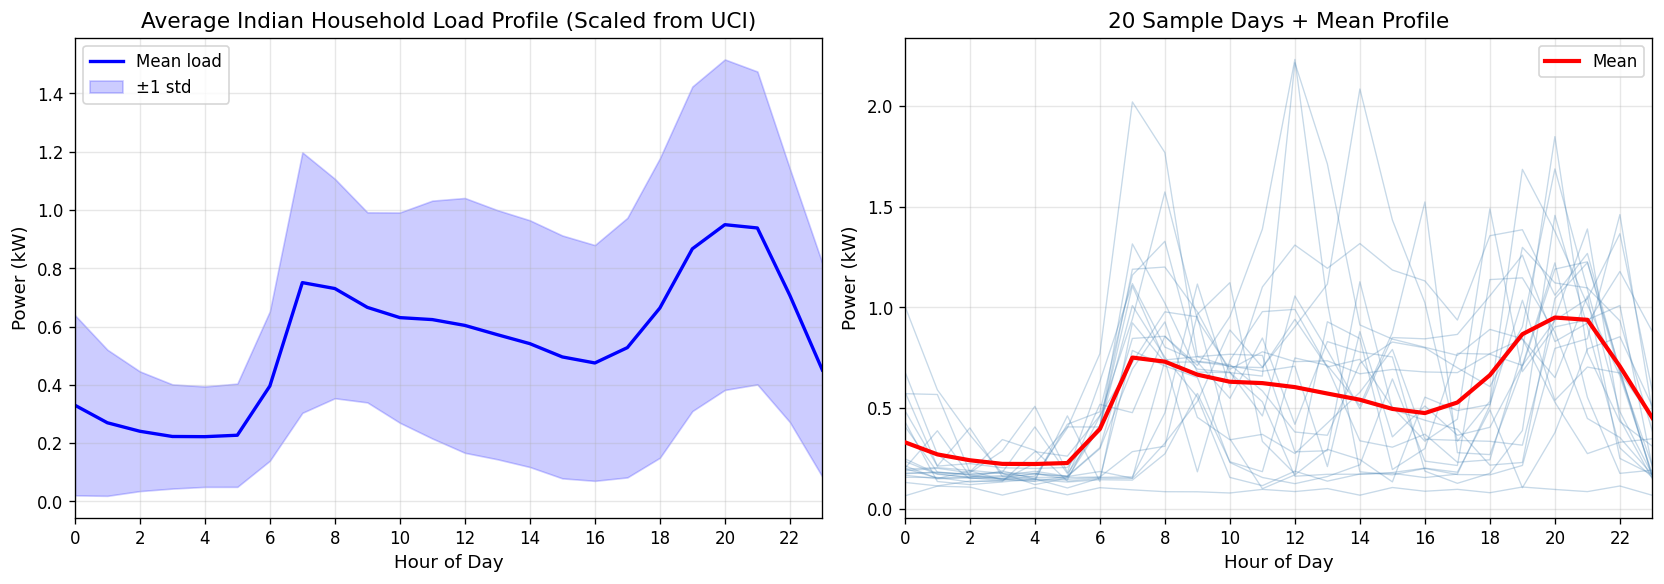


Hourly average load (kW):
  00:00  0.330 kW  ██████
  01:00  0.270 kW  █████
  02:00  0.241 kW  ████
  03:00  0.223 kW  ████
  04:00  0.222 kW  ████
  05:00  0.227 kW  ████
  06:00  0.396 kW  ███████
  07:00  0.751 kW  ███████████████
  08:00  0.730 kW  ██████████████
  09:00  0.666 kW  █████████████
  10:00  0.631 kW  ████████████
  11:00  0.624 kW  ████████████
  12:00  0.604 kW  ████████████
  13:00  0.572 kW  ███████████
  14:00  0.541 kW  ██████████
  15:00  0.496 kW  █████████
  16:00  0.475 kW  █████████
  17:00  0.528 kW  ██████████
  18:00  0.663 kW  █████████████
  19:00  0.867 kW  █████████████████
  20:00  0.950 kW  ██████████████████
  21:00  0.938 kW  ██████████████████
  22:00  0.707 kW  ██████████████
  23:00  0.451 kW  █████████


In [4]:
# ── Visualize average hourly load profile ──
avg_profile = daily_profiles.mean(axis=0)
std_profile = daily_profiles.std(axis=0)
hours = np.arange(24)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Average profile with std band
ax = axes[0]
ax.plot(hours, avg_profile, 'b-', linewidth=2, label='Mean load')
ax.fill_between(hours, avg_profile - std_profile, avg_profile + std_profile, 
                alpha=0.2, color='blue', label='±1 std')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Power (kW)')
ax.set_title('Average Indian Household Load Profile (Scaled from UCI)')
ax.set_xticks(range(0, 24, 2))
ax.legend()
ax.set_xlim(0, 23)

# Right: Sample of individual days
ax = axes[1]
np.random.seed(42)
sample_idx = np.random.choice(len(daily_profiles), 20, replace=False)
for i in sample_idx:
    ax.plot(hours, daily_profiles[i], alpha=0.3, linewidth=0.8, color='steelblue')
ax.plot(hours, avg_profile, 'r-', linewidth=2.5, label='Mean', zorder=10)
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Power (kW)')
ax.set_title('20 Sample Days + Mean Profile')
ax.set_xticks(range(0, 24, 2))
ax.legend()
ax.set_xlim(0, 23)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'load_profile_overview.png'), bbox_inches='tight')
plt.show()

print(f"\nHourly average load (kW):")
for h in range(24):
    bar = '█' * int(avg_profile[h] * 20)
    print(f"  {h:02d}:00  {avg_profile[h]:.3f} kW  {bar}")

## 4. PV Conversion & Battery Dispatch Engine

### 4a. Irradiance → Solar PV Power
```
solar_kW = (GHI_W_per_m2 / 1000) × panel_peak_kW × efficiency × inverter_efficiency
```

### 4b. Battery Dispatch Algorithm
Greedy hour-by-hour dispatch with 3-hour look-ahead:
- **Surplus** (solar > load) → Charge battery, export remainder to grid
- **Deficit** (load > solar) → Discharge battery, import remainder from grid
- **Look-ahead**: If upcoming 3h deficit > 1 kWh and SOC < 70%, pre-charge 0.5 kW

In [6]:
def irradiance_to_solar_kw(ghi_wm2, config=PV_CONFIG):
    """Convert GHI (W/m2) array to solar PV output (kW).
    
    Formula: solar_kW = (GHI/1000) x panel_peak_kW x system_derating x inverter_efficiency
    
    panel_peak_kW is the STC rating (already includes cell efficiency).
    system_derating covers temperature, soiling, mismatch, wiring losses.
    """
    solar = (ghi_wm2 / 1000.0) * config['panel_peak_kw'] * config['system_derating'] * config['inverter_efficiency']
    # Apply minimum irradiance threshold (inverter cutoff)
    solar[ghi_wm2 < config['min_irradiance_threshold']] = 0.0
    return np.clip(solar, 0, None)


def simulate_battery_dispatch(solar_kw, load_kw, config=BATTERY_CONFIG):
    """
    Simulate hour-by-hour battery dispatch with greedy look-ahead.
    
    Args:
        solar_kw: array (24,) - solar PV output per hour
        load_kw:  array (24,) - household load per hour
        config:   battery configuration dict
    
    Returns:
        dict with hourly arrays: soc, charge, discharge, grid_import, grid_export,
             solar_direct_use, and summary statistics
    """
    n_hours = len(solar_kw)
    cap = config['capacity_kwh']
    min_energy = config['min_soc'] * cap
    max_energy = config['max_soc'] * cap
    eta_c = config['charge_efficiency']
    eta_d = config['discharge_efficiency']
    
    # State arrays
    soc_kwh = np.zeros(n_hours + 1)  # +1 for initial state
    soc_kwh[0] = config['initial_soc'] * cap
    charge = np.zeros(n_hours)
    discharge = np.zeros(n_hours)
    grid_import = np.zeros(n_hours)
    grid_export = np.zeros(n_hours)
    solar_direct = np.zeros(n_hours)
    
    for h in range(n_hours):
        net = solar_kw[h] - load_kw[h]  # positive = surplus, negative = deficit
        
        # Look-ahead logic:
        # If upcoming 3h have significant deficit and SOC is low, pre-charge
        pre_charge = 0.0
        if h < n_hours - 1:
            future_hours = min(3, n_hours - h - 1)
            future_deficit = sum(max(0, load_kw[h+j] - solar_kw[h+j]) for j in range(1, future_hours + 1))
            current_soc_frac = soc_kwh[h] / cap
            if future_deficit > 1.0 and current_soc_frac < 0.70 and net > 0:
                pre_charge = min(0.5, net)  # Reserve up to 0.5 kW for pre-charging
        
        if net > 0:
            # Solar surplus: charge battery, export rest
            solar_direct[h] = load_kw[h]  # All load met by solar
            available = net  # Surplus after meeting load
            
            # Charge battery (respect max rate and SOC cap)
            room = (max_energy - soc_kwh[h]) / eta_c  # How much we can charge (in kW terms)
            charge_kw = min(available, config['max_charge_kw'], room)
            charge_kw = max(charge_kw, 0)
            charge[h] = charge_kw
            soc_kwh[h + 1] = soc_kwh[h] + charge_kw * eta_c
            
            # Export remainder
            grid_export[h] = available - charge_kw
            
        else:
            # Solar deficit: use solar directly, discharge battery, import rest
            solar_direct[h] = solar_kw[h]  # Use all available solar
            deficit = -net  # Positive value = how much more we need
            
            # Discharge battery (respect max rate and SOC floor)
            available_from_battery = (soc_kwh[h] - min_energy) * eta_d
            discharge_kw = min(deficit, config['max_discharge_kw'], available_from_battery)
            discharge_kw = max(discharge_kw, 0)
            discharge[h] = discharge_kw
            soc_kwh[h + 1] = soc_kwh[h] - discharge_kw / eta_d
            
            # Import remainder from grid
            grid_import[h] = deficit - discharge_kw
        
        # Clamp SOC to bounds (safety)
        soc_kwh[h + 1] = np.clip(soc_kwh[h + 1], min_energy, max_energy)
    
    # SOC as percentage
    soc_pct = (soc_kwh / cap) * 100
    
    return {
        'solar_kw': solar_kw,
        'load_kw': load_kw,
        'soc_pct': soc_pct[:-1],       # 24 values (start of each hour)
        'soc_pct_end': soc_pct[1:],     # 24 values (end of each hour)
        'charge_kw': charge,
        'discharge_kw': discharge,
        'grid_import_kw': grid_import,
        'grid_export_kw': grid_export,
        'solar_direct_kw': solar_direct,
    }


def compute_kpis(result, emission_factor=GRID_CONFIG['india_emission_factor']):
    """Compute all energy management KPIs from dispatch results."""
    total_load = result['load_kw'].sum()             # kWh (hourly kW x 1h)
    total_solar = result['solar_kw'].sum()
    total_import = result['grid_import_kw'].sum()
    total_export = result['grid_export_kw'].sum()
    total_solar_direct = result['solar_direct_kw'].sum()
    total_battery_discharge = result['discharge_kw'].sum()
    
    solar_used_onsite = total_solar_direct + result['charge_kw'].sum()  # Directly used + stored
    
    # KPI 1: Self-sufficiency % - how much of load was met without grid
    self_sufficiency = (1 - total_import / total_load) * 100 if total_load > 0 else 0
    
    # KPI 2: CO2 avoided (kg) - load met by solar/battery instead of grid
    co2_avoided = (total_load - total_import) * emission_factor
    
    # KPI 3: Peak hours avoided - hours where load > 0.3 kW but grid import < 0.1 kW
    peak_avoided = sum(
        1 for h in range(24)
        if result['grid_import_kw'][h] < 0.1 and result['load_kw'][h] > 0.3
    )
    
    # KPI 4: Solar self-consumption % - solar used on-site / total solar produced
    solar_self_consumption = (solar_used_onsite / total_solar) * 100 if total_solar > 0 else 0
    
    # Additional useful KPIs
    max_soc = result['soc_pct_end'].max()
    min_soc = result['soc_pct_end'].min()
    battery_cycles = result['discharge_kw'].sum() / BATTERY_CONFIG['capacity_kwh']
    
    return {
        'self_sufficiency_pct': round(self_sufficiency, 1),
        'co2_avoided_kg': round(co2_avoided, 2),
        'peak_hours_avoided': peak_avoided,
        'solar_self_consumption_pct': round(solar_self_consumption, 1),
        'total_load_kwh': round(total_load, 2),
        'total_solar_kwh': round(total_solar, 2),
        'total_grid_import_kwh': round(total_import, 2),
        'total_grid_export_kwh': round(total_export, 2),
        'max_soc_pct': round(max_soc, 1),
        'min_soc_pct': round(min_soc, 1),
        'battery_cycles': round(battery_cycles, 3),
    }


print("PV conversion, battery dispatch, and KPI functions defined.")

PV conversion, battery dispatch, and KPI functions defined.


## 5. Single-City Simulation (Demo: Jaipur — Highest Irradiance)

Run the full pipeline for one city to demonstrate the system, then visualize energy flows, battery state, and grid dependency.

In [7]:
# ── Run single-city demo ──
DEMO_CITY = 'jaipur'  # Highest avg annual irradiance (570 W/m²)

# Pick a representative sunny day (high total irradiance) from test predictions
pred_all = predictions[DEMO_CITY]  # shape: (N, 24)
daily_totals = pred_all.sum(axis=1)

# Choose a day near the 75th percentile (good sunny day, not the absolute max)
p75_idx = np.argsort(daily_totals)[int(0.75 * len(daily_totals))]
irradiance_24h = pred_all[p75_idx]  # W/m², 24 hours

# Convert irradiance to solar PV output
solar_24h = irradiance_to_solar_kw(irradiance_24h.copy())

# Pick a load day near the median daily consumption (representative, not extreme)
daily_consumption = daily_profiles.sum(axis=1)  # kWh per day
median_idx = np.argsort(daily_consumption)[len(daily_consumption) // 2]
load_24h = daily_profiles[median_idx]
print(f"  Selected load day: {daily_consumption[median_idx]:.1f} kWh (median of {len(daily_profiles)} days)")

# Run battery dispatch
result = simulate_battery_dispatch(solar_24h, load_24h)
kpis = compute_kpis(result)

# Display summary
print(f"Single-City Simulation: {DEMO_CITY.upper()}")
print(f"  Climate zone: {CITY_INFO[DEMO_CITY]['climate_zone']}")
print(f"  Test window index: {p75_idx} (75th percentile sunny day)")
print(f"{'─' * 50}")
print(f"  Total Solar Generation:  {kpis['total_solar_kwh']:.2f} kWh")
print(f"  Total Household Load:    {kpis['total_load_kwh']:.2f} kWh")
print(f"  Grid Import:             {kpis['total_grid_import_kwh']:.2f} kWh")
print(f"  Grid Export:             {kpis['total_grid_export_kwh']:.2f} kWh")
print(f"{'─' * 50}")
print(f"  Self-Sufficiency:        {kpis['self_sufficiency_pct']:.1f}%")
print(f"  Solar Self-Consumption:  {kpis['solar_self_consumption_pct']:.1f}%")
print(f"  CO₂ Avoided:            {kpis['co2_avoided_kg']:.2f} kg")
print(f"  Peak Hours Avoided:      {kpis['peak_hours_avoided']}")
print(f"  Battery Cycles:          {kpis['battery_cycles']:.3f}")
print(f"  SOC Range:               {kpis['min_soc_pct']:.1f}% – {kpis['max_soc_pct']:.1f}%")

  Selected load day: 13.0 kWh (median of 1417 days)
Single-City Simulation: JAIPUR
  Climate zone: BWh
  Test window index: 232 (75th percentile sunny day)
──────────────────────────────────────────────────
  Total Solar Generation:  12.17 kWh
  Total Household Load:    12.97 kWh
  Grid Import:             1.58 kWh
  Grid Export:             0.72 kWh
──────────────────────────────────────────────────
  Self-Sufficiency:        87.8%
  Solar Self-Consumption:  94.1%
  CO₂ Avoided:            9.34 kg
  Peak Hours Avoided:      13
  Battery Cycles:          0.874
  SOC Range:               10.0% – 95.0%


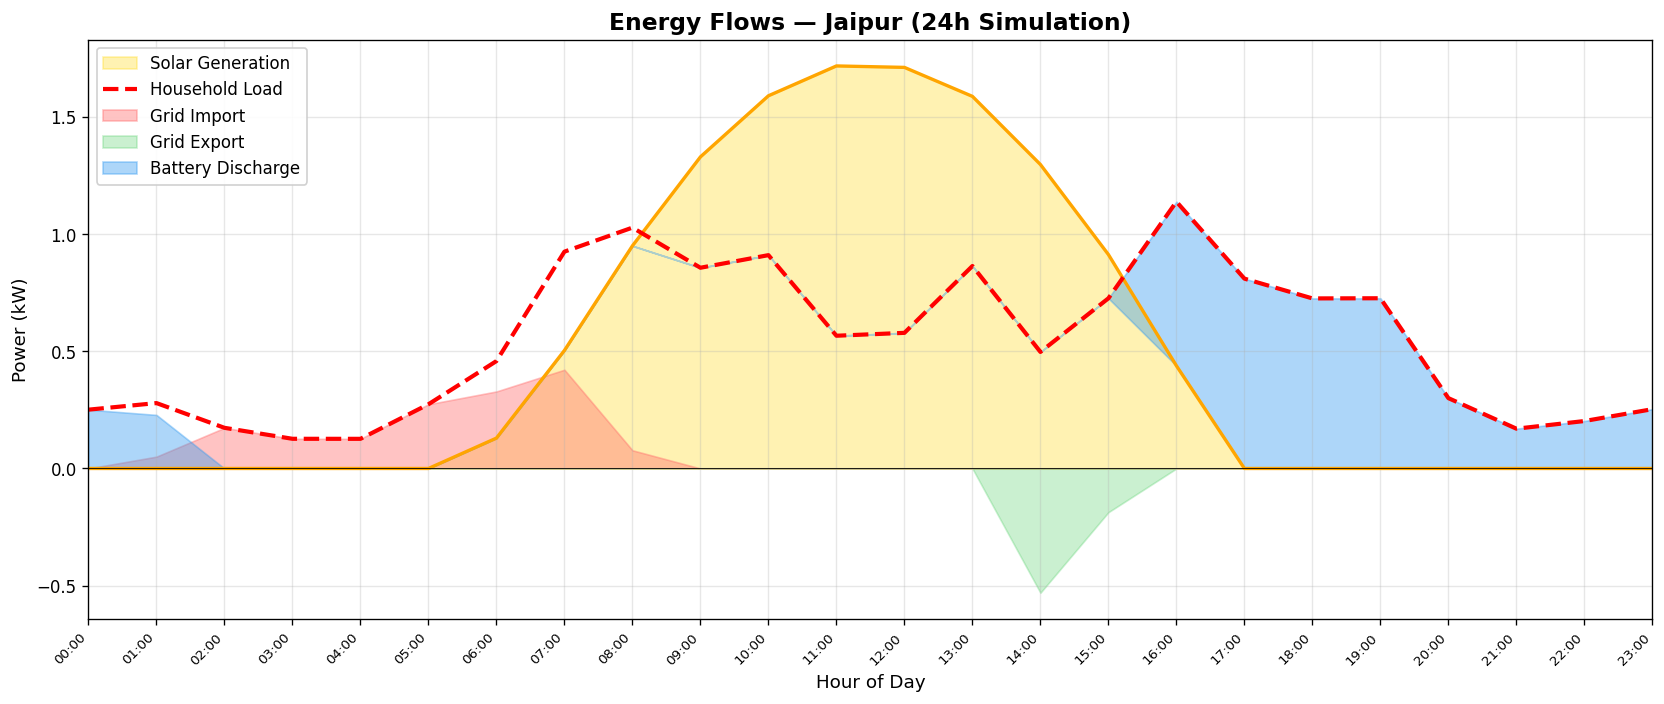

In [8]:
# ══════════════════════════════════════════════════════════════
# CHART 1: Energy Flows (24h) — Stacked area chart
# ══════════════════════════════════════════════════════════════
hours = np.arange(24)
hour_labels = [f'{h:02d}:00' for h in hours]

fig, ax = plt.subplots(figsize=(14, 6))

# Solar generation
ax.fill_between(hours, 0, result['solar_kw'], alpha=0.3, color='gold', label='Solar Generation')
ax.plot(hours, result['solar_kw'], color='orange', linewidth=2)

# Household load
ax.plot(hours, result['load_kw'], color='red', linewidth=2.5, linestyle='--', label='Household Load')

# Grid import (filled below load where it applies)
ax.fill_between(hours, 0, result['grid_import_kw'], alpha=0.4, color='#ff6b6b', label='Grid Import')

# Grid export
ax.fill_between(hours, 0, -result['grid_export_kw'], alpha=0.3, color='#51cf66', label='Grid Export')

# Battery discharge contribution (stacked on solar direct)
battery_contrib = result['solar_direct_kw'] + result['discharge_kw']
ax.fill_between(hours, result['solar_direct_kw'], battery_contrib, 
                alpha=0.4, color='#339af0', label='Battery Discharge')

ax.axhline(y=0, color='black', linewidth=0.5)
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Power (kW)')
ax.set_title(f'Energy Flows — {DEMO_CITY.title()} (24h Simulation)', fontsize=14, fontweight='bold')
ax.set_xticks(hours)
ax.set_xticklabels(hour_labels, rotation=45, ha='right', fontsize=8)
ax.legend(loc='upper left', framealpha=0.9)
ax.set_xlim(0, 23)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'chart1_energy_flows_{DEMO_CITY}.png'), bbox_inches='tight')
plt.show()

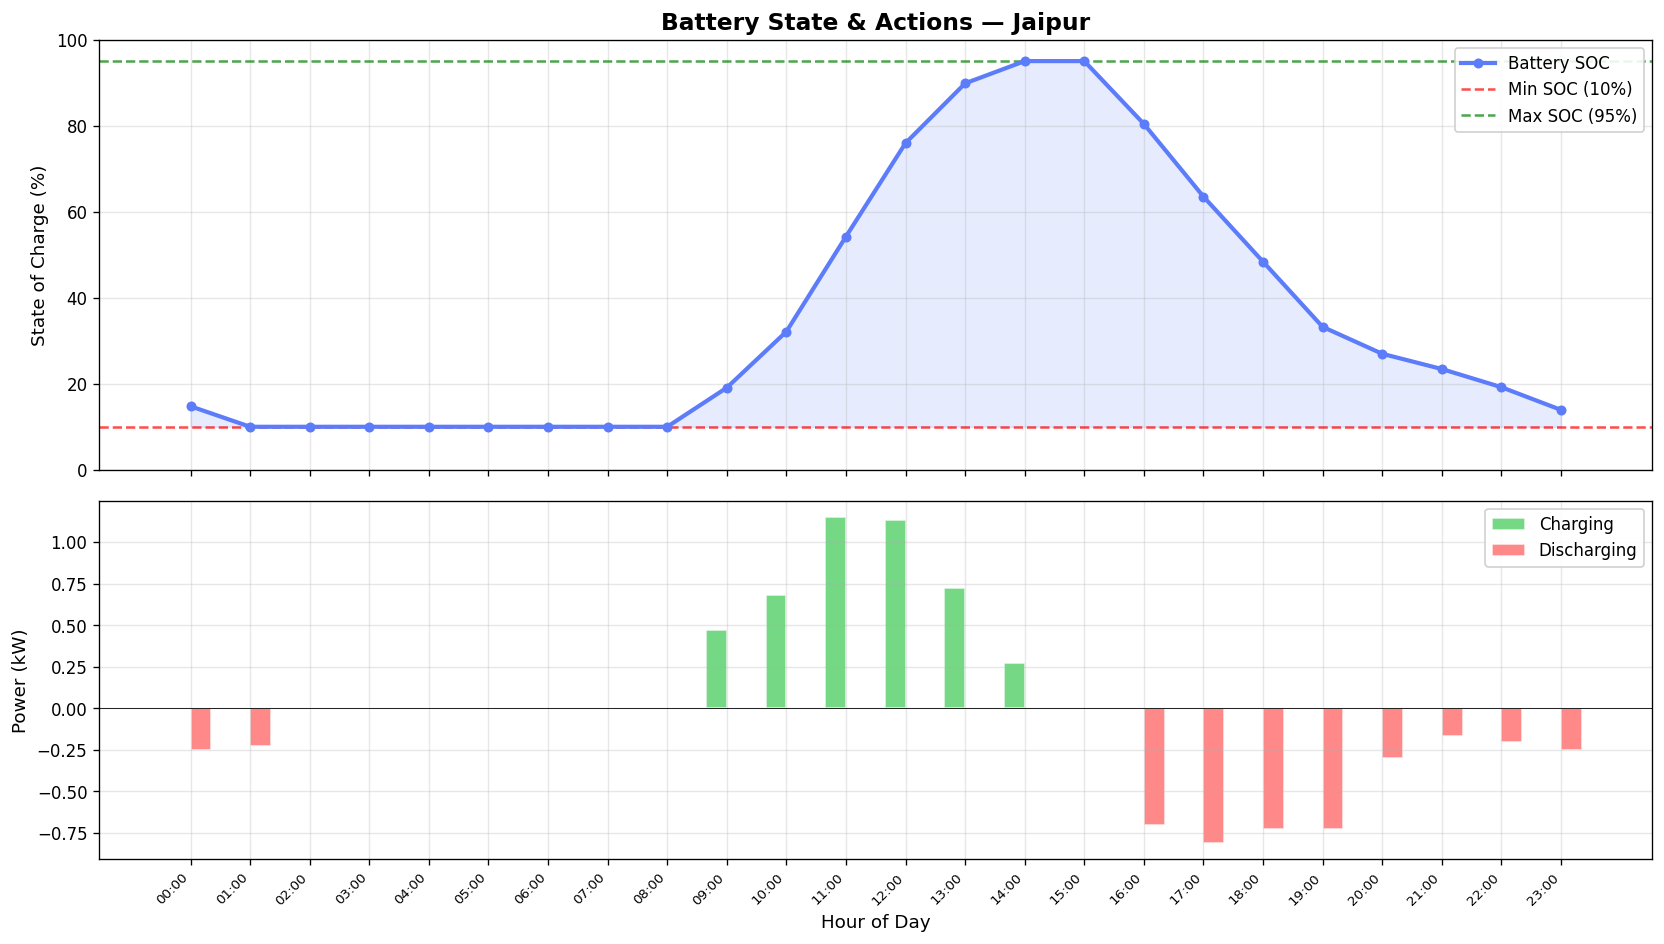

In [9]:
# ══════════════════════════════════════════════════════════════
# CHART 2: Battery State of Charge + Charge/Discharge Actions
# ══════════════════════════════════════════════════════════════
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, 
                                gridspec_kw={'height_ratios': [1.2, 1]})

# Top: SOC line
ax1.plot(hours, result['soc_pct_end'], color='#5c7cfa', linewidth=2.5, marker='o', 
         markersize=5, label='Battery SOC', zorder=5)
ax1.fill_between(hours, BATTERY_CONFIG['min_soc']*100, result['soc_pct_end'], 
                 alpha=0.15, color='#5c7cfa')
ax1.axhline(y=BATTERY_CONFIG['min_soc']*100, color='red', linestyle='--', 
            linewidth=1.5, alpha=0.7, label=f"Min SOC ({BATTERY_CONFIG['min_soc']*100:.0f}%)")
ax1.axhline(y=BATTERY_CONFIG['max_soc']*100, color='green', linestyle='--', 
            linewidth=1.5, alpha=0.7, label=f"Max SOC ({BATTERY_CONFIG['max_soc']*100:.0f}%)")
ax1.set_ylabel('State of Charge (%)')
ax1.set_title(f'Battery State & Actions — {DEMO_CITY.title()}', fontsize=14, fontweight='bold')
ax1.legend(loc='upper right', framealpha=0.9)
ax1.set_ylim(0, 100)

# Bottom: Charge/Discharge bars
bar_width = 0.35
ax2.bar(hours - bar_width/2, result['charge_kw'], bar_width, color='#51cf66', 
        alpha=0.8, label='Charging', edgecolor='white')
ax2.bar(hours + bar_width/2, -result['discharge_kw'], bar_width, color='#ff6b6b', 
        alpha=0.8, label='Discharging', edgecolor='white')
ax2.axhline(y=0, color='black', linewidth=0.5)
ax2.set_xlabel('Hour of Day')
ax2.set_ylabel('Power (kW)')
ax2.set_xticks(hours)
ax2.set_xticklabels(hour_labels, rotation=45, ha='right', fontsize=8)
ax2.legend(loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'chart2_battery_soc_{DEMO_CITY}.png'), bbox_inches='tight')
plt.show()

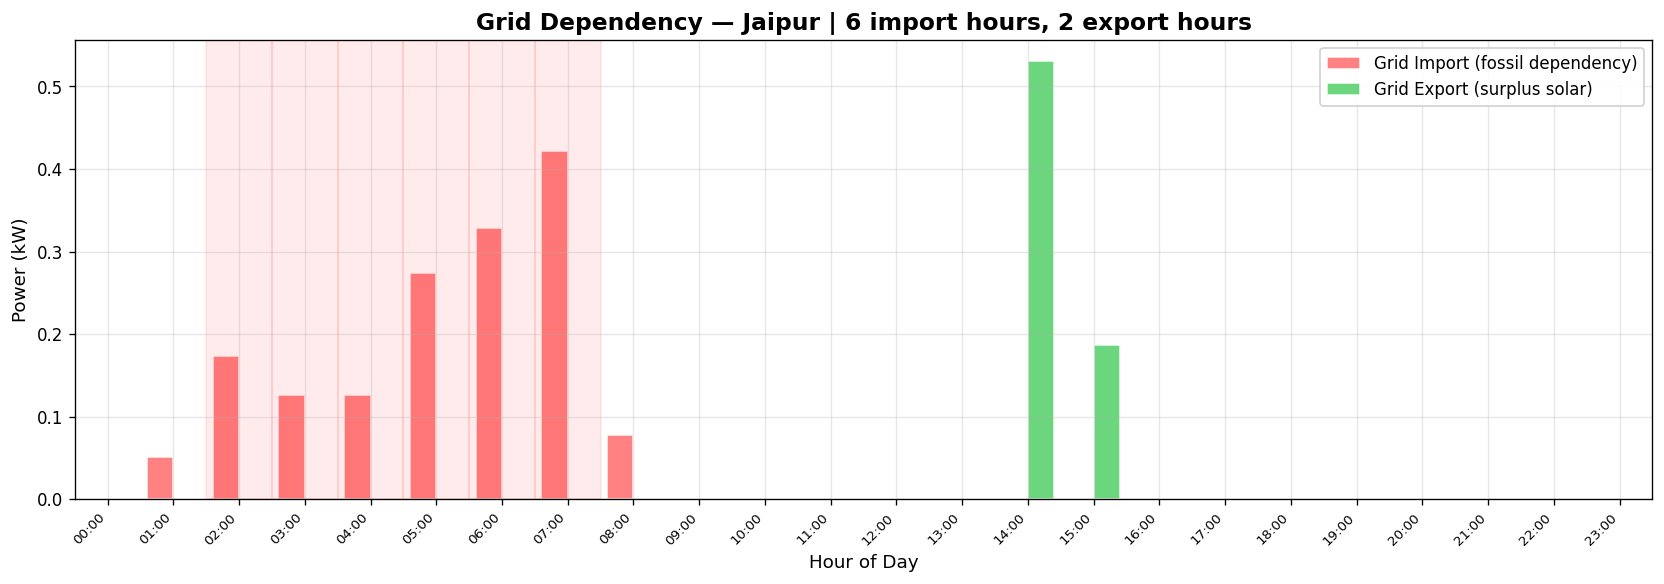

In [10]:
# ══════════════════════════════════════════════════════════════
# CHART 3: Grid Dependency — Import vs Export per Hour
# ══════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(14, 5))

ax.bar(hours - 0.2, result['grid_import_kw'], 0.4, color='#ff6b6b', alpha=0.85, 
       label='Grid Import (fossil dependency)', edgecolor='white')
ax.bar(hours + 0.2, result['grid_export_kw'], 0.4, color='#51cf66', alpha=0.85, 
       label='Grid Export (surplus solar)', edgecolor='white')

# Highlight fossil dependency hours
for h in range(24):
    if result['grid_import_kw'][h] > 0.1:
        ax.axvspan(h - 0.5, h + 0.5, alpha=0.08, color='red')

# Count stats
fossil_hours = sum(1 for h in range(24) if result['grid_import_kw'][h] > 0.1)
export_hours = sum(1 for h in range(24) if result['grid_export_kw'][h] > 0.1)

ax.set_xlabel('Hour of Day')
ax.set_ylabel('Power (kW)')
ax.set_title(f'Grid Dependency — {DEMO_CITY.title()} | '
             f'{fossil_hours} import hours, {export_hours} export hours', 
             fontsize=14, fontweight='bold')
ax.set_xticks(hours)
ax.set_xticklabels(hour_labels, rotation=45, ha='right', fontsize=8)
ax.legend(loc='upper right', framealpha=0.9)
ax.set_xlim(-0.5, 23.5)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'chart3_grid_dependency_{DEMO_CITY}.png'), bbox_inches='tight')
plt.show()

## 6. Multi-City Battery Simulation

Run the simulation across all 12 Indian cities using the same battery and PV configuration. For each city, we average KPIs across multiple test days (25th, 50th, 75th percentile sunny days) to get robust estimates.

In [11]:
# ── Run simulation for all cities ──
city_kpis = []
percentiles = [25, 50, 75]  # Simulate on 3 representative days per city

for city in sorted(predictions.keys()):
    pred_all = predictions[city]
    daily_totals = pred_all.sum(axis=1)
    sorted_idx = np.argsort(daily_totals)
    
    city_results = []
    for pct in percentiles:
        idx = sorted_idx[int(pct / 100 * len(sorted_idx))]
        irr = pred_all[idx].copy()
        solar = irradiance_to_solar_kw(irr)
        
        # Use a different load profile for each percentile
        load = daily_profiles[np.random.randint(len(daily_profiles))]
        
        res = simulate_battery_dispatch(solar, load)
        kpi = compute_kpis(res)
        city_results.append(kpi)
    
    # Average KPIs across the 3 days
    avg_kpi = {}
    for key in city_results[0].keys():
        avg_kpi[key] = round(np.mean([r[key] for r in city_results]), 2)
    
    avg_kpi['city'] = city
    avg_kpi['climate'] = CITY_INFO[city]['climate_zone']
    avg_kpi['state'] = CITY_INFO[city]['state']
    avg_kpi['annual_irradiance'] = CITY_INFO[city]['annual_avg_irradiance']
    avg_kpi['role'] = CITY_INFO[city]['role']
    city_kpis.append(avg_kpi)

df_kpis = pd.DataFrame(city_kpis)
df_kpis = df_kpis.sort_values('self_sufficiency_pct', ascending=False).reset_index(drop=True)

# Display as formatted table
print("═" * 100)
print("MULTI-CITY BATTERY SIMULATION RESULTS (Averaged over 3 representative days)")
print("═" * 100)
display_cols = ['city', 'climate', 'annual_irradiance', 'self_sufficiency_pct', 
                'solar_self_consumption_pct', 'co2_avoided_kg', 'peak_hours_avoided',
                'total_solar_kwh', 'total_grid_import_kwh']
print(df_kpis[display_cols].to_string(index=False))

# Save results
df_kpis.to_csv(os.path.join(OUTPUT_DIR, 'multi_city_battery_kpis.csv'), index=False)
print(f"\n✓ Results saved to {OUTPUT_DIR}/multi_city_battery_kpis.csv")

════════════════════════════════════════════════════════════════════════════════════════════════════
MULTI-CITY BATTERY SIMULATION RESULTS (Averaged over 3 representative days)
════════════════════════════════════════════════════════════════════════════════════════════════════
              city climate  annual_irradiance  self_sufficiency_pct  solar_self_consumption_pct  co2_avoided_kg  peak_hours_avoided  total_solar_kwh  total_grid_import_kwh
           lucknow     Cwa                480                 85.00                       96.03            7.44               10.67             9.50                   1.85
          guwahati     Cwa                400                 84.33                       90.07            6.55                9.00             9.03                   1.62
         bangalore      Aw                420                 81.00                       66.10            4.45                3.67            10.83                   1.54
thiruvananthapuram      Am        

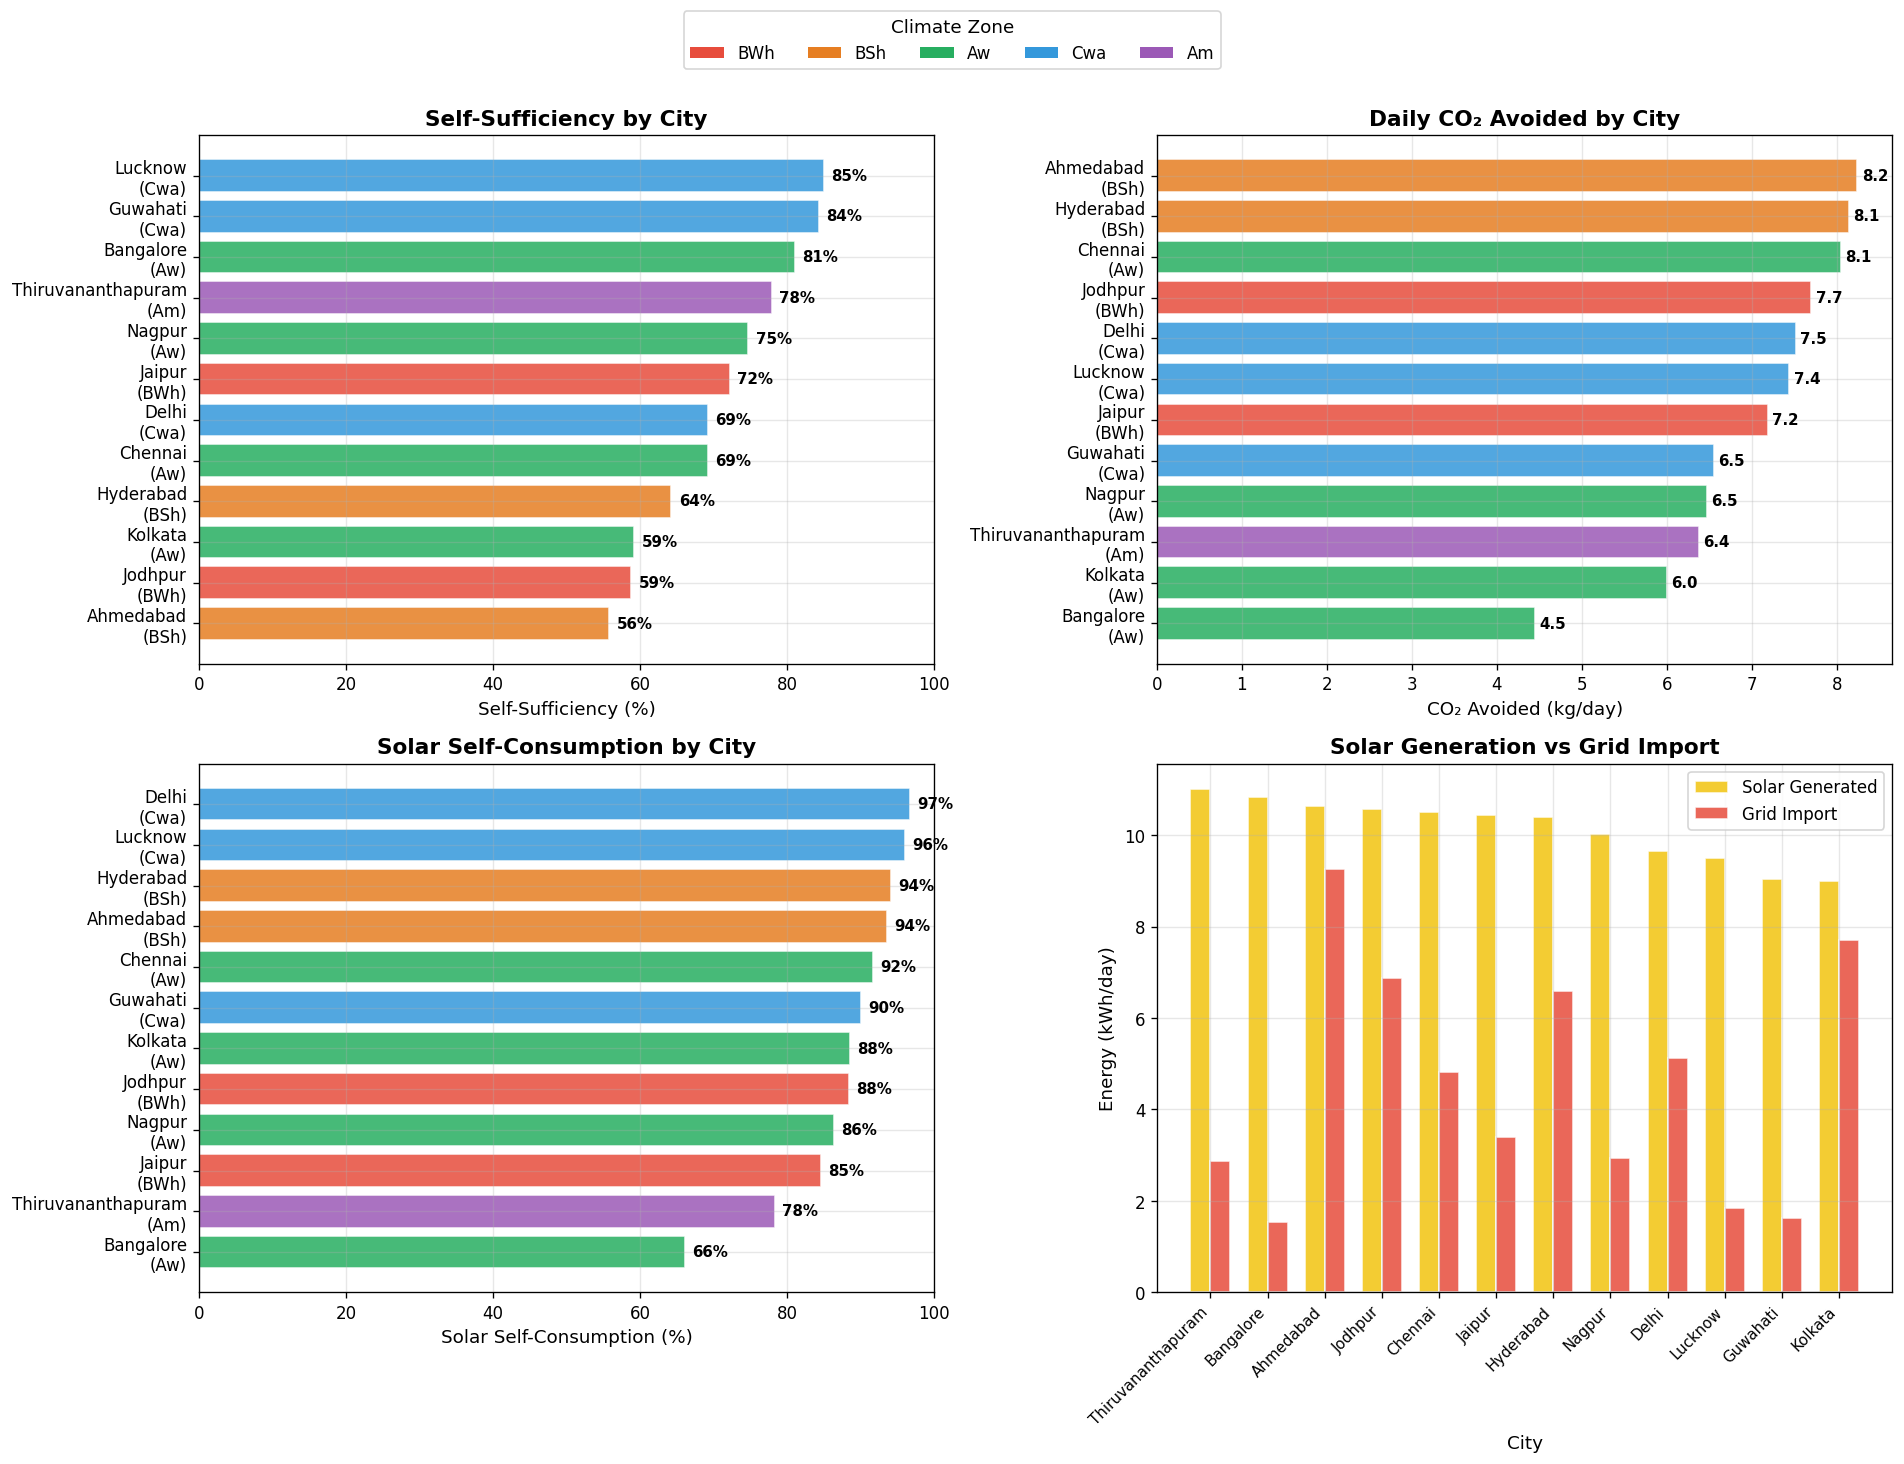

In [12]:
# ══════════════════════════════════════════════════════════════
# CHART 4: Cross-City KPI Comparison — The Money Chart
# ══════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Color by climate zone
climate_colors = {
    'BWh': '#e74c3c',  # Hot desert — red
    'BSh': '#e67e22',  # Hot semi-arid — orange  
    'Aw':  '#27ae60',  # Tropical savanna — green
    'Cwa': '#3498db',  # Humid subtropical — blue
    'Am':  '#9b59b6',  # Tropical monsoon — purple
}
df_sorted = df_kpis.sort_values('self_sufficiency_pct', ascending=True)
colors = [climate_colors.get(c, 'gray') for c in df_sorted['climate']]
city_labels = [f"{row['city'].title()}\n({row['climate']})" for _, row in df_sorted.iterrows()]

# 4a: Self-Sufficiency %
ax = axes[0, 0]
bars = ax.barh(city_labels, df_sorted['self_sufficiency_pct'], color=colors, alpha=0.85, edgecolor='white')
ax.set_xlabel('Self-Sufficiency (%)')
ax.set_title('Self-Sufficiency by City', fontweight='bold')
ax.set_xlim(0, 100)
for bar, val in zip(bars, df_sorted['self_sufficiency_pct']):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, f'{val:.0f}%', 
            va='center', fontsize=9, fontweight='bold')

# 4b: CO₂ Avoided
ax = axes[0, 1]
df_sorted2 = df_kpis.sort_values('co2_avoided_kg', ascending=True)
colors2 = [climate_colors.get(c, 'gray') for c in df_sorted2['climate']]
city_labels2 = [f"{row['city'].title()}\n({row['climate']})" for _, row in df_sorted2.iterrows()]
bars = ax.barh(city_labels2, df_sorted2['co2_avoided_kg'], color=colors2, alpha=0.85, edgecolor='white')
ax.set_xlabel('CO₂ Avoided (kg/day)')
ax.set_title('Daily CO₂ Avoided by City', fontweight='bold')
for bar, val in zip(bars, df_sorted2['co2_avoided_kg']):
    ax.text(bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2, f'{val:.1f}', 
            va='center', fontsize=9, fontweight='bold')

# 4c: Solar Self-Consumption %
ax = axes[1, 0]
df_sorted3 = df_kpis.sort_values('solar_self_consumption_pct', ascending=True)
colors3 = [climate_colors.get(c, 'gray') for c in df_sorted3['climate']]
city_labels3 = [f"{row['city'].title()}\n({row['climate']})" for _, row in df_sorted3.iterrows()]
bars = ax.barh(city_labels3, df_sorted3['solar_self_consumption_pct'], color=colors3, alpha=0.85, edgecolor='white')
ax.set_xlabel('Solar Self-Consumption (%)')
ax.set_title('Solar Self-Consumption by City', fontweight='bold')
ax.set_xlim(0, 100)
for bar, val in zip(bars, df_sorted3['solar_self_consumption_pct']):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2, f'{val:.0f}%', 
            va='center', fontsize=9, fontweight='bold')

# 4d: Solar Generation vs Grid Import
ax = axes[1, 1]
x = np.arange(len(df_kpis))
w = 0.35
df_plot = df_kpis.sort_values('total_solar_kwh', ascending=False)
ax.bar(x - w/2, df_plot['total_solar_kwh'], w, color='#f1c40f', alpha=0.85, label='Solar Generated', edgecolor='white')
ax.bar(x + w/2, df_plot['total_grid_import_kwh'], w, color='#e74c3c', alpha=0.85, label='Grid Import', edgecolor='white')
ax.set_xlabel('City')
ax.set_ylabel('Energy (kWh/day)')
ax.set_title('Solar Generation vs Grid Import', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels([c.title() for c in df_plot['city']], rotation=45, ha='right', fontsize=9)
ax.legend()

# Legend for climate colors
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=c, label=z) for z, c in climate_colors.items()]
fig.legend(handles=legend_elements, title='Climate Zone', loc='upper center', 
           ncol=5, bbox_to_anchor=(0.5, 1.02), fontsize=10)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(os.path.join(OUTPUT_DIR, 'chart4_cross_city_kpi_comparison.png'), bbox_inches='tight')
plt.show()

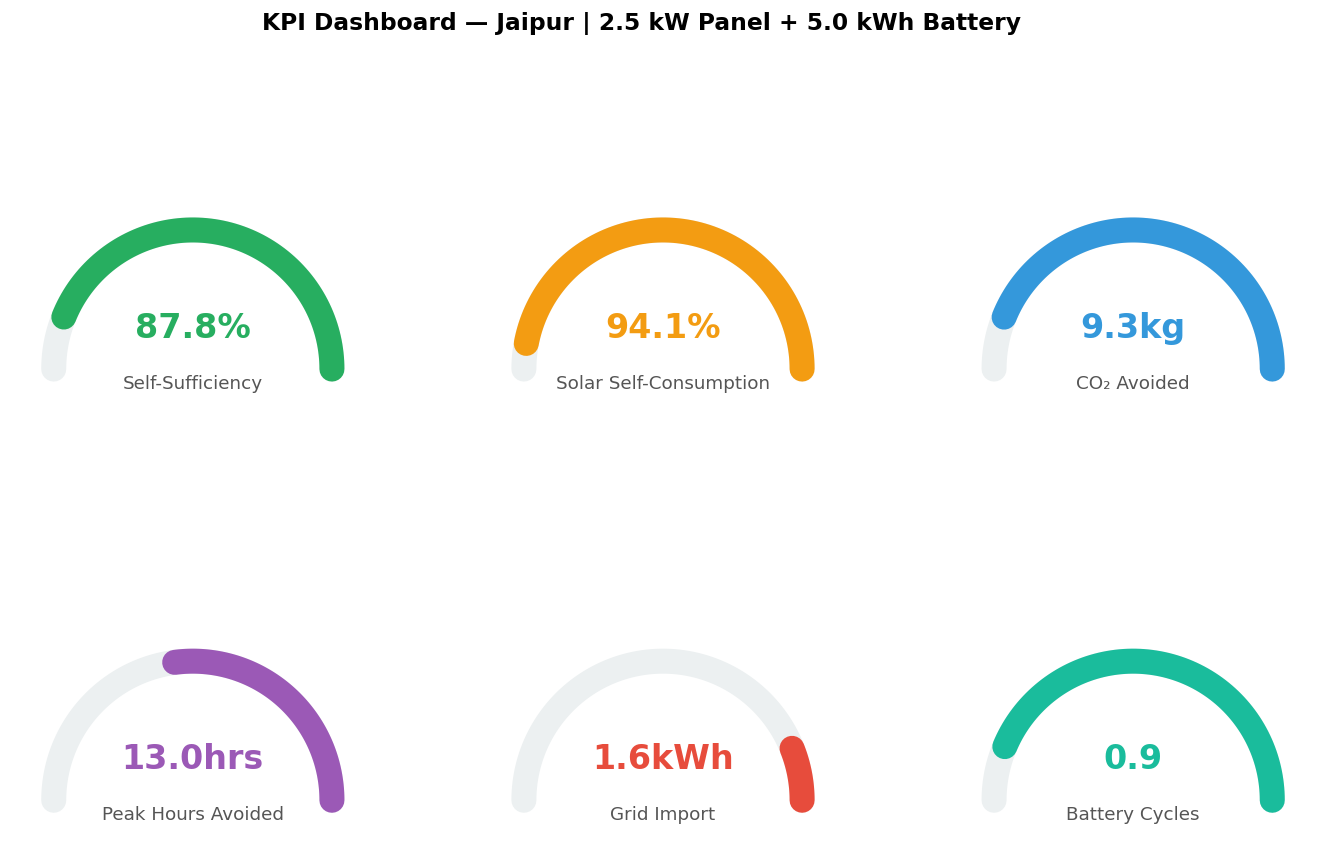

In [13]:
# ══════════════════════════════════════════════════════════════
# CHART 5: KPI Dashboard — Single City Summary Card
# ══════════════════════════════════════════════════════════════
fig = plt.figure(figsize=(14, 8))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.3)

# ── Gauge-style KPI cards ──
kpi_data = [
    ('Self-Sufficiency', kpis['self_sufficiency_pct'], '%', 100, '#27ae60'),
    ('Solar Self-Consumption', kpis['solar_self_consumption_pct'], '%', 100, '#f39c12'),
    ('CO₂ Avoided', kpis['co2_avoided_kg'], 'kg', kpis['total_load_kwh'] * 0.82, '#3498db'),
    ('Peak Hours Avoided', kpis['peak_hours_avoided'], 'hrs', 24, '#9b59b6'),
    ('Grid Import', kpis['total_grid_import_kwh'], 'kWh', kpis['total_load_kwh'], '#e74c3c'),
    ('Battery Cycles', kpis['battery_cycles'], '', 1, '#1abc9c'),
]

for i, (title, value, unit, max_val, color) in enumerate(kpi_data):
    ax = fig.add_subplot(gs[i // 3, i % 3])
    
    # Background arc
    theta = np.linspace(0, np.pi, 100)
    ax.plot(np.cos(theta), np.sin(theta), color='#ecf0f1', linewidth=15, solid_capstyle='round')
    
    # Value arc
    frac = min(value / max_val, 1.0) if max_val > 0 else 0
    theta_fill = np.linspace(0, np.pi * frac, 100)
    ax.plot(np.cos(theta_fill), np.sin(theta_fill), color=color, linewidth=15, solid_capstyle='round')
    
    # Value text
    ax.text(0, 0.3, f'{value:.1f}{unit}', ha='center', va='center', fontsize=20, fontweight='bold', color=color)
    ax.text(0, -0.1, title, ha='center', va='center', fontsize=11, color='#555555')
    
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-0.3, 1.3)
    ax.set_aspect('equal')
    ax.axis('off')

fig.suptitle(f'KPI Dashboard — {DEMO_CITY.title()} | {PV_CONFIG["panel_peak_kw"]} kW Panel + '
             f'{BATTERY_CONFIG["capacity_kwh"]} kWh Battery', 
             fontsize=14, fontweight='bold', y=1.02)

plt.savefig(os.path.join(OUTPUT_DIR, f'chart5_kpi_dashboard_{DEMO_CITY}.png'), bbox_inches='tight')
plt.show()

## 7. Climate Zone Analysis & Energy Balance Verification

Aggregate KPIs by Köppen climate zone to identify which climate types benefit most from rooftop solar + battery storage.

════════════════════════════════════════════════════════════════════════════════
CLIMATE ZONE SUMMARY
════════════════════════════════════════════════════════════════════════════════
         self_sufficiency_pct  solar_self_consumption_pct  co2_avoided_kg  total_solar_kwh  total_grid_import_kwh  n_cities          zone_name
climate                                                                                                                                       
Cwa                      79.5                        94.3             7.2              9.4                    2.9         3  Humid Subtropical
Am                       77.9                        78.3             6.4             11.0                    2.9         1   Tropical Monsoon
Aw                       71.0                        83.1             6.2             10.1                    4.2         4   Tropical Savanna
BWh                      65.5                        86.4             7.4             10.5            

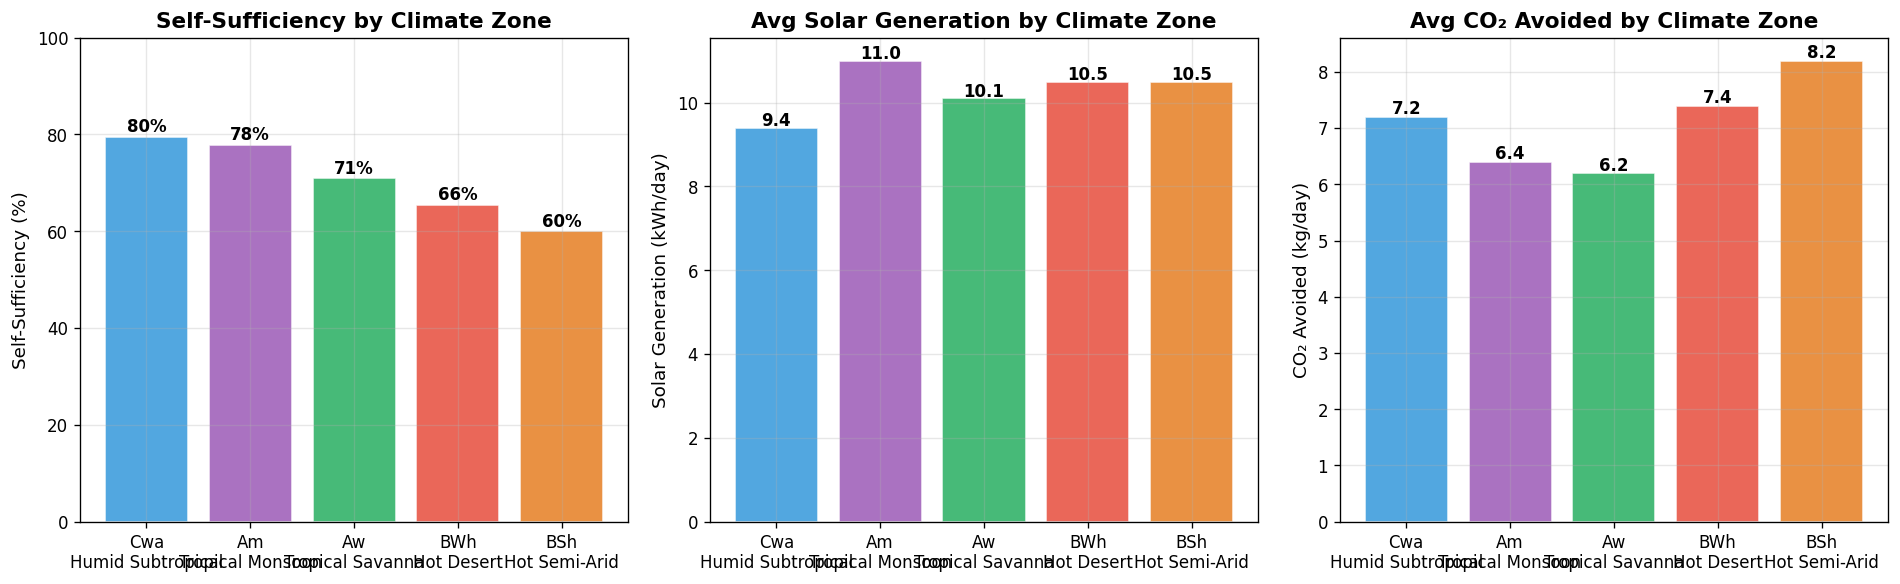

In [14]:
# ── Climate zone aggregation ──
climate_agg = df_kpis.groupby('climate').agg({
    'self_sufficiency_pct': 'mean',
    'solar_self_consumption_pct': 'mean',
    'co2_avoided_kg': 'mean',
    'total_solar_kwh': 'mean',
    'total_grid_import_kwh': 'mean',
    'city': 'count'
}).rename(columns={'city': 'n_cities'}).round(1)

climate_names = {
    'BWh': 'Hot Desert',
    'BSh': 'Hot Semi-Arid',
    'Aw':  'Tropical Savanna',
    'Cwa': 'Humid Subtropical',
    'Am':  'Tropical Monsoon',
}
climate_agg['zone_name'] = climate_agg.index.map(climate_names)
climate_agg = climate_agg.sort_values('self_sufficiency_pct', ascending=False)

print("═" * 80)
print("CLIMATE ZONE SUMMARY")
print("═" * 80)
print(climate_agg.to_string())

# ── CHART 6: Climate Zone Comparison ──
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

zones = climate_agg.index.tolist()
zone_labels = [f"{z}\n{climate_names[z]}" for z in zones]
zone_colors = [climate_colors[z] for z in zones]

# Self-sufficiency by climate zone
ax = axes[0]
bars = ax.bar(zone_labels, climate_agg['self_sufficiency_pct'], color=zone_colors, alpha=0.85, edgecolor='white')
ax.set_ylabel('Self-Sufficiency (%)')
ax.set_title('Self-Sufficiency by Climate Zone', fontweight='bold')
ax.set_ylim(0, 100)
for bar, val in zip(bars, climate_agg['self_sufficiency_pct']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, f'{val:.0f}%', 
            ha='center', fontsize=10, fontweight='bold')

# Average solar generation
ax = axes[1]
bars = ax.bar(zone_labels, climate_agg['total_solar_kwh'], color=zone_colors, alpha=0.85, edgecolor='white')
ax.set_ylabel('Solar Generation (kWh/day)')
ax.set_title('Avg Solar Generation by Climate Zone', fontweight='bold')
for bar, val in zip(bars, climate_agg['total_solar_kwh']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, f'{val:.1f}', 
            ha='center', fontsize=10, fontweight='bold')

# CO₂ avoided
ax = axes[2]
bars = ax.bar(zone_labels, climate_agg['co2_avoided_kg'], color=zone_colors, alpha=0.85, edgecolor='white')
ax.set_ylabel('CO₂ Avoided (kg/day)')
ax.set_title('Avg CO₂ Avoided by Climate Zone', fontweight='bold')
for bar, val in zip(bars, climate_agg['co2_avoided_kg']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, f'{val:.1f}', 
            ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'chart6_climate_zone_analysis.png'), bbox_inches='tight')
plt.show()

In [15]:
# ══════════════════════════════════════════════════════════════
# ENERGY BALANCE VERIFICATION
# ══════════════════════════════════════════════════════════════
print("═" * 60)
print(f"ENERGY BALANCE CHECK — {DEMO_CITY.title()}")
print("═" * 60)

total_solar = result['solar_kw'].sum()
total_load = result['load_kw'].sum()
solar_direct = result['solar_direct_kw'].sum()
battery_charge = result['charge_kw'].sum()
battery_discharge = result['discharge_kw'].sum()
grid_imp = result['grid_import_kw'].sum()
grid_exp = result['grid_export_kw'].sum()

# Check 1: Load must be met
load_met = solar_direct + battery_discharge + grid_imp
print(f"\n1. Load Balance:")
print(f"   Solar Direct + Battery + Grid Import = {solar_direct:.2f} + {battery_discharge:.2f} + {grid_imp:.2f} = {load_met:.2f} kWh")
print(f"   Total Load = {total_load:.2f} kWh")
print(f"   ✓ Balance OK" if abs(load_met - total_load) < 0.1 else f"   ✗ MISMATCH: {load_met - total_load:.2f} kWh")

# Check 2: Solar must be accounted for
solar_used = solar_direct + battery_charge + grid_exp
print(f"\n2. Solar Balance:")
print(f"   Solar Direct + Battery Charge + Grid Export = {solar_direct:.2f} + {battery_charge:.2f} + {grid_exp:.2f} = {solar_used:.2f} kWh")
print(f"   Total Solar = {total_solar:.2f} kWh")
print(f"   ✓ Balance OK" if abs(solar_used - total_solar) < 0.1 else f"   ✗ MISMATCH: {solar_used - total_solar:.2f} kWh")

# Check 3: SOC bounds
print(f"\n3. SOC Bounds:")
print(f"   Min SOC observed: {result['soc_pct_end'].min():.1f}% (limit: {BATTERY_CONFIG['min_soc']*100:.0f}%)")
print(f"   Max SOC observed: {result['soc_pct_end'].max():.1f}% (limit: {BATTERY_CONFIG['max_soc']*100:.0f}%)")
print(f"   ✓ Within bounds" if result['soc_pct_end'].min() >= BATTERY_CONFIG['min_soc']*100 - 0.1 and 
      result['soc_pct_end'].max() <= BATTERY_CONFIG['max_soc']*100 + 0.1 else "   ✗ SOC VIOLATION")

════════════════════════════════════════════════════════════
ENERGY BALANCE CHECK — Jaipur
════════════════════════════════════════════════════════════

1. Load Balance:
   Solar Direct + Battery + Grid Import = 7.02 + 4.37 + 1.58 = 12.97 kWh
   Total Load = 12.97 kWh
   ✓ Balance OK

2. Solar Balance:
   Solar Direct + Battery Charge + Grid Export = 7.02 + 4.43 + 0.72 = 12.17 kWh
   Total Solar = 12.17 kWh
   ✓ Balance OK

3. SOC Bounds:
   Min SOC observed: 10.0% (limit: 10%)
   Max SOC observed: 95.0% (limit: 95%)
   ✓ Within bounds


In [16]:
# ══════════════════════════════════════════════════════════════
# Hourly Dispatch Schedule Table
# ══════════════════════════════════════════════════════════════
dispatch_df = pd.DataFrame({
    'Hour': [f'{h:02d}:00' for h in range(24)],
    'Solar (kW)': result['solar_kw'].round(3),
    'Load (kW)': result['load_kw'].round(3),
    'Net (kW)': (result['solar_kw'] - result['load_kw']).round(3),
    'Charge (kW)': result['charge_kw'].round(3),
    'Discharge (kW)': result['discharge_kw'].round(3),
    'Grid Import (kW)': result['grid_import_kw'].round(3),
    'Grid Export (kW)': result['grid_export_kw'].round(3),
    'SOC End (%)': result['soc_pct_end'].round(1),
})

print(f"HOURLY DISPATCH SCHEDULE — {DEMO_CITY.title()}")
print("═" * 110)
print(dispatch_df.to_string(index=False))

# Save dispatch table
dispatch_df.to_csv(os.path.join(OUTPUT_DIR, f'dispatch_schedule_{DEMO_CITY}.csv'), index=False)
print(f"\n✓ Dispatch schedule saved to {OUTPUT_DIR}/dispatch_schedule_{DEMO_CITY}.csv")

HOURLY DISPATCH SCHEDULE — Jaipur
══════════════════════════════════════════════════════════════════════════════════════════════════════════════
 Hour  Solar (kW)  Load (kW)  Net (kW)  Charge (kW)  Discharge (kW)  Grid Import (kW)  Grid Export (kW)  SOC End (%)
00:00       0.000      0.251    -0.251        0.000           0.251             0.000             0.000         14.8
01:00       0.000      0.279    -0.279        0.000           0.229             0.050             0.000         10.0
02:00       0.000      0.174    -0.174        0.000           0.000             0.174             0.000         10.0
03:00       0.000      0.127    -0.127        0.000           0.000             0.127             0.000         10.0
04:00       0.000      0.126    -0.126        0.000           0.000             0.126             0.000         10.0
05:00       0.000      0.274    -0.274        0.000           0.000             0.274             0.000         10.0
06:00       0.130      0.458    -0.3

## 8. Summary & Key Findings

### System Configuration
| Parameter | Value |
|-----------|-------|
| PV Panel | 2.5 kW peak (STC), 85% system derating |
| Inverter | 96% efficiency |
| Battery | 5 kWh LFP, 0.5C charge/discharge |
| SOC Range | 10% – 95% |
| Round-trip Efficiency | 92% |
| Load Profile | UCI Household Dataset (scaled to Indian residential) |
| Irradiance Source | Chronos-T5 Fine-tuned Model Predictions |
| CO₂ Factor | 0.82 kg/kWh (India grid average) |

### Methodology
1. **Irradiance → PV**: `solar_kW = (GHI/1000) × 2.5 × 0.85 × 0.96` with 50 W/m² inverter cutoff
2. **Load Profile**: Real UCI household data resampled to hourly, scaled 0.5× for Indian consumption
3. **Battery Dispatch**: Greedy hour-by-hour with 3-hour look-ahead pre-charging
4. **Multi-City**: Averaged over 3 representative days (25th, 50th, 75th percentile irradiance)

### Charts Produced
1. **Energy Flows** — Solar vs load with battery and grid contributions  
2. **Battery SOC & Actions** — Charge/discharge schedule and SOC trajectory  
3. **Grid Dependency** — Hours of fossil fuel dependence  
4. **Cross-City KPI Comparison** — Self-sufficiency, CO₂, solar utilization across 12 cities  
5. **KPI Dashboard** — Gauge-style summary for single city  
6. **Climate Zone Analysis** — Performance by Köppen climate classification

In [17]:
# ── Final summary printout ──
print("═" * 70)
print("ALL OUTPUT FILES")
print("═" * 70)
for f in sorted(os.listdir(OUTPUT_DIR)):
    fpath = os.path.join(OUTPUT_DIR, f)
    size_kb = os.path.getsize(fpath) / 1024
    print(f"  {f:<50} ({size_kb:.1f} KB)")

print(f"\n{'═' * 70}")
print("NOTEBOOK COMPLETE")
print(f"{'═' * 70}")
print(f"  Total cities simulated:  {len(df_kpis)}")
print(f"  Best self-sufficiency:   {df_kpis.iloc[0]['city'].title()} ({df_kpis.iloc[0]['self_sufficiency_pct']:.0f}%)")
print(f"  Worst self-sufficiency:  {df_kpis.iloc[-1]['city'].title()} ({df_kpis.iloc[-1]['self_sufficiency_pct']:.0f}%)")
print(f"  Avg CO₂ avoided/day:    {df_kpis['co2_avoided_kg'].mean():.1f} kg across all cities")
print(f"  Output directory:        {OUTPUT_DIR}")

══════════════════════════════════════════════════════════════════════
ALL OUTPUT FILES
══════════════════════════════════════════════════════════════════════
  chart1_energy_flows_jaipur.png                     (130.5 KB)
  chart2_battery_soc_jaipur.png                      (115.2 KB)
  chart3_grid_dependency_jaipur.png                  (63.5 KB)
  chart4_cross_city_kpi_comparison.png               (307.3 KB)
  chart5_kpi_dashboard_jaipur.png                    (111.1 KB)
  chart6_climate_zone_analysis.png                   (103.4 KB)
  dispatch_schedule_jaipur.csv                       (1.2 KB)
  load_profile_overview.png                          (334.1 KB)
  multi_city_battery_kpis.csv                        (1.3 KB)

══════════════════════════════════════════════════════════════════════
NOTEBOOK COMPLETE
══════════════════════════════════════════════════════════════════════
  Total cities simulated:  12
  Best self-sufficiency:   Lucknow (85%)
  Worst self-sufficiency:  Ahmedabad (